# 01 — Exploración de datos

Fase 1.2 del plan. Estadísticas y ejemplos de los cuatro datasets antes de unificarlos:
CODEBRIM, NEU-DET, RDD2022 (subconjunto Japón) y MVTec AD (4 categorías del `training_config.yaml`).

Objetivo: entender formatos de anotación, distribución de clases, tamaños de imagen y de caja,
para justificar la taxonomía unificada de la fase 2.1.

## 0. Configuración de rutas

In [1]:
import sys
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils.paths import load_paths, load_training_config

P = load_paths()
RAW = P["raw"]
MV = RAW["mvtec"]
CFG = load_training_config()
MV_CATS = CFG["unsupervised"]["mvtec_categories"]

for name, path in RAW.items():
    print(f"{name:10s} {path}  existe={path.exists()}")

codebrim   C:\Users\urkow\Documents\Github\inspectai-industrial-cv\data\raw\codebrim  existe=True
neu_surface C:\Users\urkow\Documents\Github\inspectai-industrial-cv\data\raw\neu_surface  existe=True
rdd2022    C:\Users\urkow\Documents\Github\inspectai-industrial-cv\data\raw\rdd2022  existe=True
mvtec      C:\Users\urkow\Documents\Github\inspectai-industrial-cv\data\raw\mvtec  existe=True


## 1. Funciones de lectura

Las anotaciones de NEU-DET, RDD2022 y CODEBRIM son Pascal VOC (XML). Esta función las convierte
en dos tablas: una por imagen y otra por caja.

In [2]:
def read_voc(xml_dir):
    img_rows, box_rows = [], []
    for x in sorted(xml_dir.glob("*.xml")):
        r = ET.parse(x).getroot()
        s = r.find("size")
        w, h = int(s.findtext("width")), int(s.findtext("height"))
        objs = r.findall("object")
        img_rows.append({"image": x.stem, "w": w, "h": h, "n_obj": len(objs)})
        for o in objs:
            bb = o.find("bndbox")
            x0, y0, x1, y1 = (int(float(bb.findtext(k))) for k in ("xmin", "ymin", "xmax", "ymax"))
            box_rows.append({
                "image": x.stem, "cls": o.findtext("name"), "w": w, "h": h,
                "xmin": x0, "ymin": y0, "xmax": x1, "ymax": y1,
                "bw": x1 - x0, "bh": y1 - y0, "area_frac": (x1 - x0) * (y1 - y0) / (w * h),
            })
    return pd.DataFrame(img_rows), pd.DataFrame(box_rows)


def show_samples(samples, cols=3):
    rows = -(-len(samples) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (path, boxes, title) in zip(axes, samples):
        im = Image.open(path)
        ax.imshow(im, cmap="gray" if im.mode == "L" else None)
        for x0, y0, x1, y1 in boxes:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red", lw=1.5))
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()

## 2. CODEBRIM (hormigón, 6 clases de daño)

Cada objeto tiene la etiqueta `defect` y, dentro de `<Defect>`, flags binarios por tipo de daño.
Un mismo objeto puede tener varios flags activos (multietiqueta).

In [3]:
cb_dir = RAW["codebrim"]
cb_imgs = {p.stem for p in (cb_dir / "images").glob("*.jpg")}
cb_xml = sorted((cb_dir / "annotations").glob("*.xml"))
cb_anns = {x.stem for x in cb_xml}
print(f"imágenes: {len(cb_imgs)} | XML: {len(cb_anns)} | con par: {len(cb_imgs & cb_anns)} | imágenes sin XML: {len(cb_imgs - cb_anns)}")

FLAGS = ["Background", "Crack", "Spallation", "Efflorescence", "ExposedBars", "CorrosionStain"]
cb_flag_counts, cb_box_combo = Counter(), []
for x in cb_xml:
    for o in ET.parse(x).getroot().findall("object"):
        d = o.find("Defect")
        active = [f for f in FLAGS if d is not None and d.findtext(f, "0").strip() == "1"]
        cb_flag_counts.update(active)
        cb_box_combo.append("+".join(active) or "ninguna")

print("\nObjetos por clase (multietiqueta):")
print(pd.Series(dict(cb_flag_counts)).sort_values(ascending=False))
print("\nCombinaciones más frecuentes:")
print(pd.Series(cb_box_combo).value_counts().head(10))

imágenes: 1590 | XML: 1052 | con par: 1052 | imágenes sin XML: 538



Objetos por clase (multietiqueta):
Crack             2502
Spallation        1892
CorrosionStain    1550
ExposedBars       1502
Efflorescence      828
Background          49
dtype: int64

Combinaciones más frecuentes:
Crack                                    2036
Spallation+ExposedBars+CorrosionStain     786
Efflorescence                             516
Spallation+ExposedBars                    434
Spallation                                307
CorrosionStain                            260
Crack+Spallation                          107
Crack+Efflorescence                       105
Spallation+CorrosionStain                  99
ExposedBars                                82
Name: count, dtype: int64


In [4]:
cb_img, cb_box = read_voc(cb_dir / "annotations")
print("Tamaños de imagen (w x h):")
print(cb_img.groupby(["w", "h"]).size().sort_values(ascending=False).head(10))
print("\nImágenes sin objetos:", (cb_img.n_obj == 0).sum())
print("\nObjetos por imagen:")
print(cb_img.n_obj.describe())
print("\nFracción del área de la imagen ocupada por cada caja:")
print(cb_box.area_frac.describe())

Tamaños de imagen (w x h):
w     h   
4608  3456    591
6000  3376    100
      4000     76
2816  2112     50
2272  1704     48
3648  2736     35
1904  2856     18
1972  2960     18
2736  3648     15
2592  1944     15
dtype: int64

Imágenes sin objetos: 28

Objetos por imagen:
count    1052.000000
mean        4.974335
std         4.528408
min         0.000000
25%         2.000000
50%         4.000000
75%         7.000000
max        48.000000
Name: n_obj, dtype: float64

Fracción del área de la imagen ocupada por cada caja:
count    5233.000000
mean        0.061644
std         0.136723
min         0.000147
25%         0.007333
50%         0.018551
75%         0.049694
max         0.999494
Name: area_frac, dtype: float64


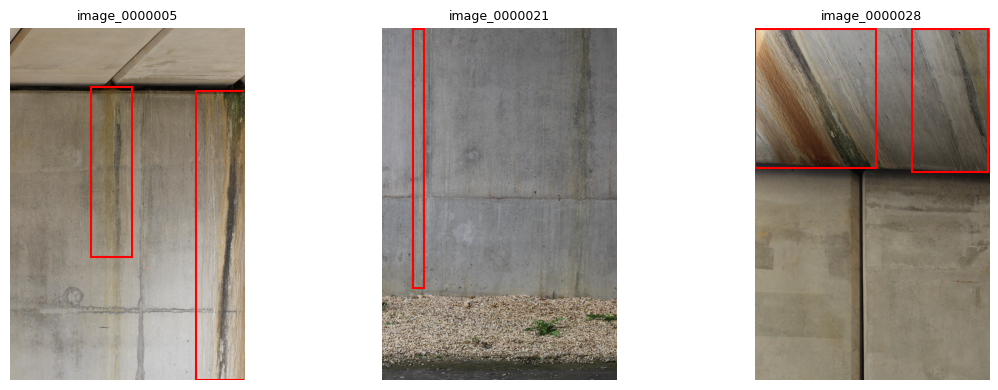

In [5]:
ok = cb_img[cb_img.n_obj > 0].image.head(3).tolist()
samples = []
for stem in ok:
    path = cb_dir / "images" / f"{stem}.jpg"
    boxes = cb_box.loc[cb_box.image == stem, ["xmin", "ymin", "xmax", "ymax"]].values.tolist()
    if path.exists():
        samples.append((path, boxes, stem))
show_samples(samples)

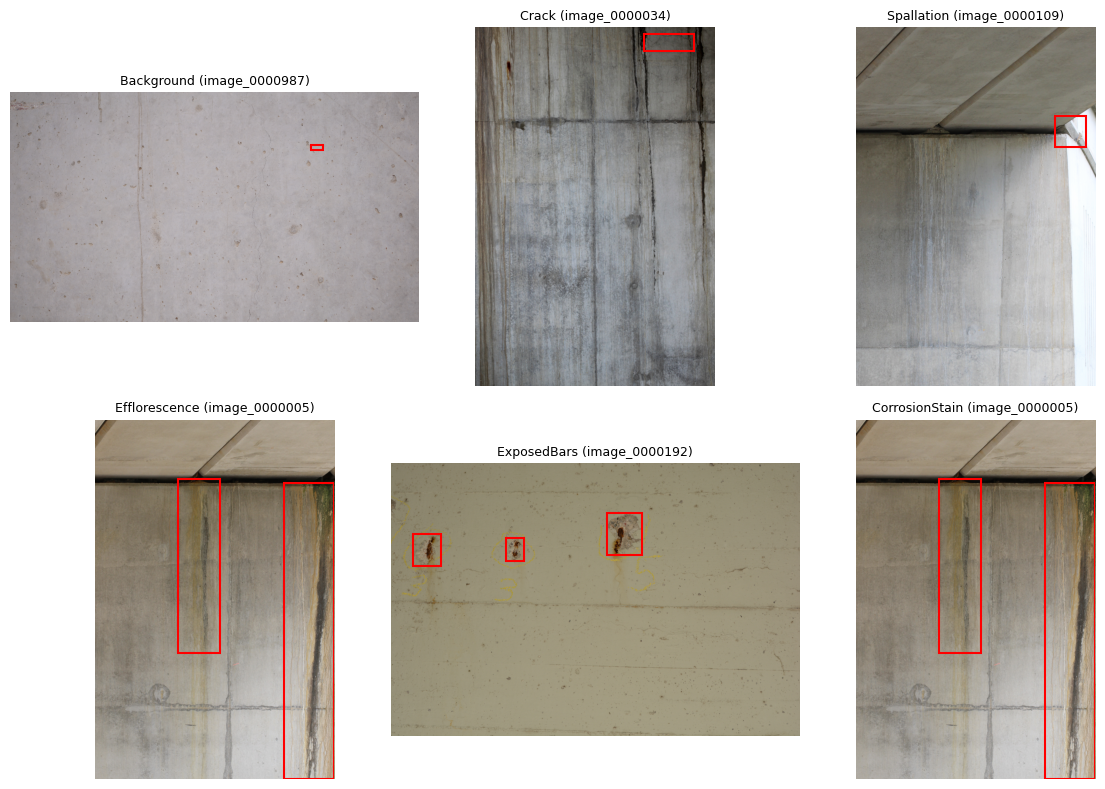

In [6]:
# Un ejemplo por clase de daño. Cada objeto es multietiqueta, así que se dibujan solo las cajas
# que tienen activo el flag buscado. cb_box_combo sigue el mismo orden que las filas de cb_box
# (XML ordenados por nombre y objetos en orden de aparición).
cb_box["combo"] = cb_box_combo
samples = []
for flag in FLAGS:
    cand = cb_box[cb_box.combo.str.split("+").apply(lambda xs: flag in xs)]
    if cand.empty:
        continue
    stem = cand.image.iloc[0]
    path = cb_dir / "images" / f"{stem}.jpg"
    boxes = cand.loc[cand.image == stem, ["xmin", "ymin", "xmax", "ymax"]].values.tolist()
    if path.exists():
        samples.append((path, boxes, f"{flag} ({stem})"))
show_samples(samples)

## 3. NEU-DET (acero, 6 clases)

Imágenes de 200×200 en escala de grises. Cada XML tiene un objeto por defecto con su caja.
Para la fase 4 comprobamos si las cajas son informativas o cubren casi toda la imagen.

In [7]:
neu_dir = RAW["neu_surface"]
neu_img, neu_box = read_voc(neu_dir / "ANNOTATIONS")
print("Imágenes en XML:", len(neu_img), "| objetos:", len(neu_box))
print("\nClases:")
print(neu_box.cls.value_counts())
print("\nTamaños (w x h):")
print(neu_img.groupby(["w", "h"]).size())
print("\nFracción del área ocupada por la caja:")
print(neu_box.area_frac.describe())
print("\nCajas que cubren más del 90 % de la imagen:", (neu_box.area_frac > 0.9).mean().round(3))

Imágenes en XML: 1800 | objetos: 4189

Clases:
cls
inclusion          1011
patches             881
crazing             689
rolled-in_scale     628
scratches           548
pitted_surface      432
Name: count, dtype: int64

Tamaños (w x h):
w    h  
200  200    1800
dtype: int64

Fracción del área ocupada por la caja:
count    4189.000000
mean        0.174505
std         0.188652
min         0.002700
25%         0.051300
50%         0.117875
75%         0.219075
max         0.990025
Name: area_frac, dtype: float64

Cajas que cubren más del 90 % de la imagen: 0.02


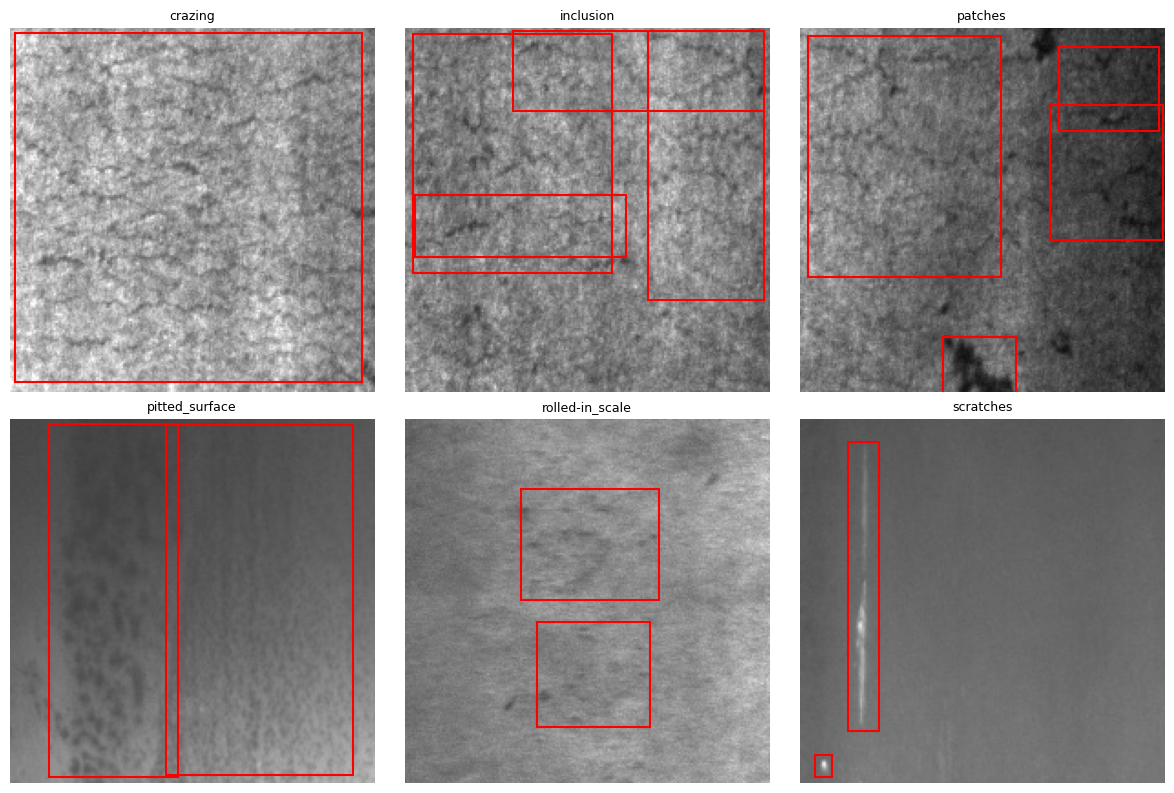

In [8]:
samples = []
for cls in sorted(neu_box.cls.unique()):
    stem = neu_box.loc[neu_box.cls == cls, "image"].iloc[0]
    path = neu_dir / "IMAGES" / f"{stem}.jpg"
    boxes = neu_box.loc[neu_box.image == stem, ["xmin", "ymin", "xmax", "ymax"]].values.tolist()
    if path.exists():
        samples.append((path, boxes, cls))
show_samples(samples)

## 4. RDD2022 (pavimento, subconjunto Japón)

Solo usamos `Japan/train`, que es la parte con anotaciones. `Japan/test` no trae XML.

Ojo: el `label_map.pbtxt` oficial define 4 clases (D00, D10, D20, D40), pero los XML de Japón
incluyen además D43, D44 y D50. La celda siguiente cuantifica cuántas cajas quedan fuera del mapa oficial.

In [9]:
rdd_dir = RAW["rdd2022"] / "Japan" / "train"
rdd_imgs = {p.stem for p in (rdd_dir / "images").glob("*.jpg")}
rdd_xml = sorted((rdd_dir / "annotations" / "xmls").glob("*.xml"))
rdd_anns = {x.stem for x in rdd_xml}
print(f"imágenes: {len(rdd_imgs)} | XML: {len(rdd_anns)} | con par: {len(rdd_imgs & rdd_anns)} | sin XML: {len(rdd_imgs - rdd_anns)}")

rdd_img, rdd_box = read_voc(rdd_dir / "annotations" / "xmls")
print("\nClases:")
print(rdd_box.cls.value_counts())

# El label_map.pbtxt oficial de CRDDC solo define D00, D10, D20 y D40.
RDD_OFICIALES = {"D00", "D10", "D20", "D40"}
fuera = rdd_box[~rdd_box.cls.isin(RDD_OFICIALES)]
print(f"\nCajas con clases fuera del label_map oficial ({sorted(fuera.cls.unique())}): "
      f"{len(fuera)} de {len(rdd_box)} ({len(fuera) / len(rdd_box):.1%})")
print("\nImágenes sin objetos:", (rdd_img.n_obj == 0).sum())
print("\nTamaños (w x h):")
print(rdd_img.groupby(["w", "h"]).size().sort_values(ascending=False).head(5))
print("\nFracción del área ocupada por la caja:")
print(rdd_box.area_frac.describe())

imágenes: 10506 | XML: 10506 | con par: 10506 | sin XML: 0

Clases:
cls
D20    6199
D00    4049
D44    3995
D10    3979
D50    3553
D40    2243
D43     736
Name: count, dtype: int64

Cajas con clases fuera del label_map oficial (['D43', 'D44', 'D50']): 8284 de 24754 (33.5%)

Imágenes sin objetos: 794

Tamaños (w x h):
w     h   
600   600     10187
1024  1024      147
540   540       124
1080  1080       48
dtype: int64

Fracción del área ocupada por la caja:
count    24754.000000
mean         0.059167
std          0.089990
min          0.000000
25%          0.005585
50%          0.019061
75%          0.076515
max          0.940847
Name: area_frac, dtype: float64


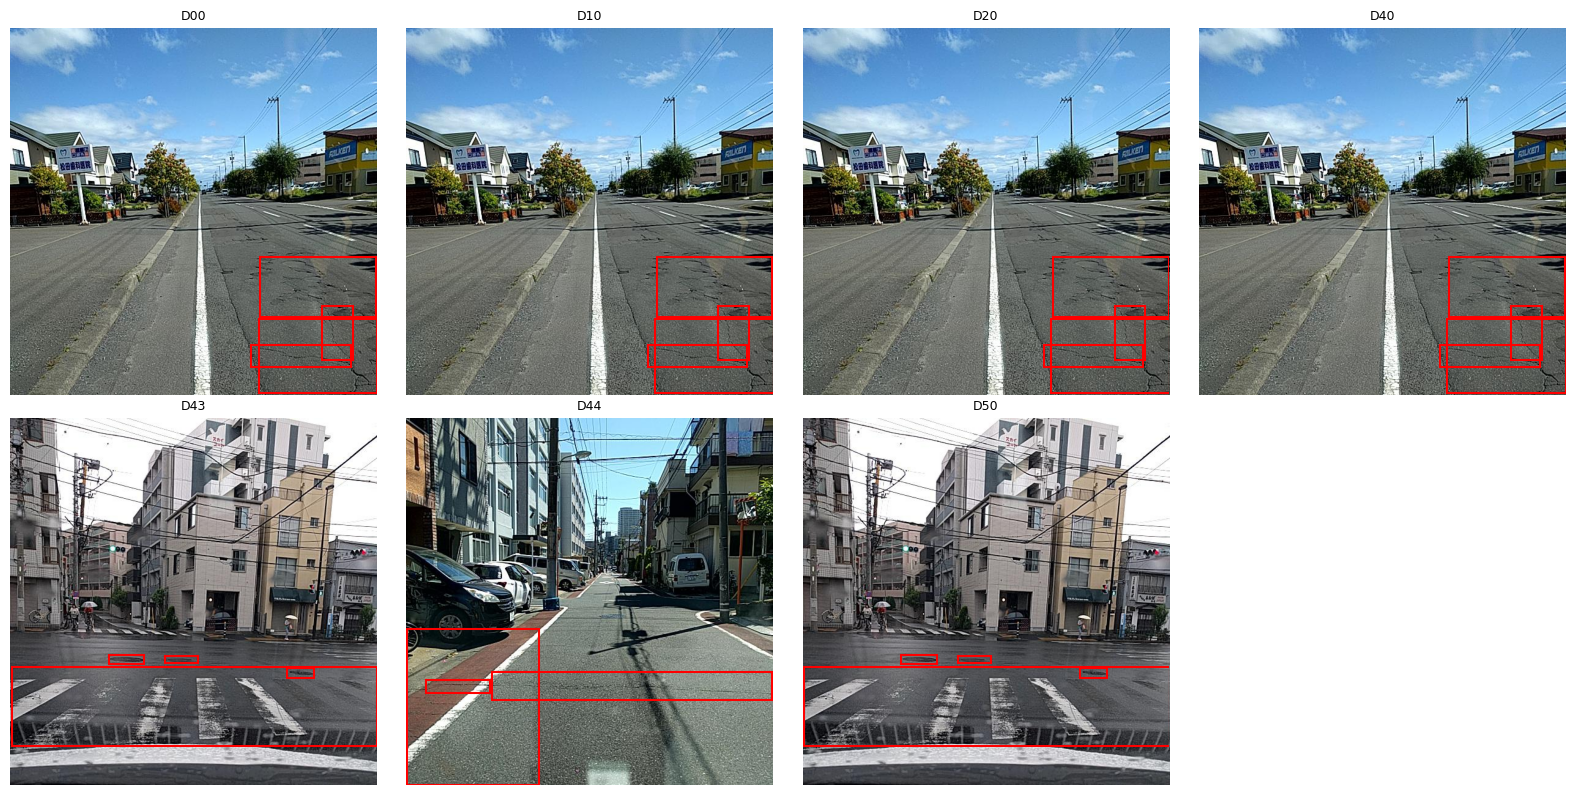

In [10]:
samples = []
for cls in sorted(rdd_box.cls.unique()):
    stem = rdd_box.loc[rdd_box.cls == cls, "image"].iloc[0]
    path = rdd_dir / "images" / f"{stem}.jpg"
    boxes = rdd_box.loc[rdd_box.image == stem, ["xmin", "ymin", "xmax", "ymax"]].values.tolist()
    if path.exists():
        samples.append((path, boxes, cls))
show_samples(samples, cols=4)

## 5. MVTec AD (anomalías, 4 categorías)

Entrenamiento solo con `good`. En `test` hay imágenes normales y defectos, y cada defecto tiene máscara en `ground_truth`.

In [11]:
rows = []
for c in MV_CATS:
    for split in ["train", "test"]:
        for d in sorted((MV / c / split).iterdir()):
            if d.is_dir():
                rows.append({"cat": c, "split": split, "tipo": d.name,
                             "n": len(list(d.glob("*.png")))})
mv_df = pd.DataFrame(rows)
display(mv_df.pivot_table(index=["cat", "tipo"], columns="split", values="n", fill_value=0))

split                          test  train
cat       tipo                            
carpet    color                19.0    0.0
          cut                  17.0    0.0
          good                 28.0  280.0
          hole                 17.0    0.0
          metal_contamination  17.0    0.0
          thread               19.0    0.0
grid      bent                 12.0    0.0
          broken               12.0    0.0
          glue                 11.0    0.0
          good                 21.0  264.0
          metal_contamination  11.0    0.0
          thread               11.0    0.0
metal_nut bent                 25.0    0.0
          color                22.0    0.0
          flip                 23.0    0.0
          good                 22.0  220.0
          scratch              23.0    0.0
tile      crack                17.0    0.0
          glue_strip           18.0    0.0
          good                 33.0  230.0
          gray_stroke          16.0    0.0
          oil                  18.0    0.0
          rough                15.0    0.0

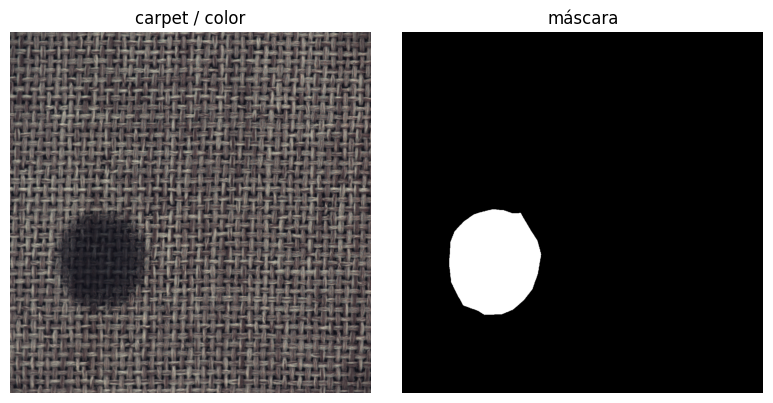

Tamaño imagen: (1024, 1024) | modo: RGB


In [12]:
c = MV_CATS[0]
defect_dir = next(d for d in sorted((MV / c / "test").iterdir()) if d.is_dir() and d.name != "good")
img_path = sorted(defect_dir.glob("*.png"))[0]
mask_path = MV / c / "ground_truth" / defect_dir.name / f"{img_path.stem}_mask.png"

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(img_path))
axes[0].set_title(f"{c} / {defect_dir.name}")
axes[1].imshow(Image.open(mask_path), cmap="gray")
axes[1].set_title("máscara")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Tamaño imagen:", Image.open(img_path).size, "| modo:", Image.open(img_path).mode)

## 6. Resumen comparativo

Tabla para la sección 3 del README y para `DATA_CARD.md`.

In [13]:
def count(folder, pattern):
    return len(list(folder.glob(pattern)))

summary = pd.DataFrame([
    {"dataset": "CODEBRIM", "imágenes": len(cb_imgs), "anotadas (XML)": len(cb_anns),
     "formato": "Pascal VOC + flags", "clases": len(FLAGS), "tamaños": cb_img.groupby(["w", "h"]).ngroups},
    {"dataset": "NEU-DET", "imágenes": count(neu_dir / "IMAGES", "*.jpg"),
     "anotadas (XML)": len(neu_img), "formato": "Pascal VOC",
     "clases": neu_box.cls.nunique(), "tamaños": neu_img.groupby(["w", "h"]).ngroups},
    {"dataset": "RDD2022 Japón (train)", "imágenes": len(rdd_imgs), "anotadas (XML)": len(rdd_anns),
     "formato": "Pascal VOC", "clases": rdd_box.cls.nunique(), "tamaños": rdd_img.groupby(["w", "h"]).ngroups},
    {"dataset": "MVTec AD (4 cats.)", "imágenes": int(mv_df.n.sum()), "anotadas (XML)": "—",
     "formato": "PNG + máscaras", "clases": "—", "tamaños": "—"},
])
display(summary)

,dataset,imágenes,anotadas (XML),formato,clases,tamaños
0,CODEBRIM,1590,1052,Pascal VOC + flags,6,26
1,NEU-DET,1800,1800,Pascal VOC,6,1
2,RDD2022 Japón (train),10506,10506,Pascal VOC,7,4
3,MVTec AD (4 cats.),1421,—,PNG + máscaras,—,—


## 7. Observaciones

Completar tras revisar las salidas:
- Desbalance de clases en cada dataset.
- Diferencias de escala y tamaño de caja entre dominios.
- Imágenes sin anotación y cómo se tratan.
- Decisión provisional sobre la taxonomía de la fase 2.1.